# Depth Anything Update Case 3

## 1. Setup and Configuration

In [1]:
import gc
import importlib.util
import json
import math
import os
import sys
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import display
from PIL import Image, ImageDraw

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "data" / "depthanything_update_case3"
IMAGE_DIR = OUTPUT_DIR / "sequence_images"
MODEL_DIR = OUTPUT_DIR / "model_outputs"
VIS_DIR = OUTPUT_DIR / "visualizations"
for directory in [OUTPUT_DIR, IMAGE_DIR, MODEL_DIR, VIS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
for local_package in [
    PROJECT_ROOT / "external" / "Depth-Anything-3" / "src",
    PROJECT_ROOT / "external" / "sam3",
]:
    if local_package.exists() and str(local_package) not in sys.path:
        sys.path.insert(0, str(local_package))

IDOT_ITEM_ID = "474c97d9a5074e8fbe09268f79ee39be"
TARGET_OBJECTID = 5
ANCHOR_MAPILLARY_IMAGE_ID = "534536254383108"
MAX_SEQUENCE_DISTANCE_TO_GT_M = 230.0
MAX_ANCHOR_DISTANCE_TO_GT_M = 60.0
MIN_SEQUENCE_FRAMES = 3
MAX_SEQUENCE_FRAMES = 9

DA3_MODEL_ID = "depth-anything/DA3NESTED-GIANT-LARGE-1.1"
LOCAL_SAM3_CHECKPOINT = PROJECT_ROOT / "data" / "model_weights" / "sam3.pt"
SAM3_PROMPTS = [
    "overhead highway sign",
    "green highway road sign",
    "overhead sign gantry",
    "sign truss",
]
ROAD_PROMPT = "road surface"
MIN_SAM3_SCORE = 0.25
MIN_MEASURABLE_OBJECT_AREA_FRACTION = 0.01
FORCE_RERUN_MODELS = False

MAPILLARY_TOKEN = os.getenv("MAPILLARY_TOKEN", "").strip()
if not MAPILLARY_TOKEN:
    raise RuntimeError(
        "Set MAPILLARY_TOKEN in the environment before running this notebook. "
        "The token is used only for automated Mapillary metadata/image retrieval."
    )

pd.set_option("display.max_columns", 80)
print("Output directory:", OUTPUT_DIR)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("DA3 installed:", importlib.util.find_spec("depth_anything_3") is not None)
print("SAM3 installed:", importlib.util.find_spec("sam3") is not None)

Output directory: D:\18463\Desktop\capstone\data\depthanything_update_case3
Device: cuda
DA3 installed: True
SAM3 installed: True


## 2. Load the IDOT Vertical-Clearance Ground Truth Automatically

In [2]:
def arcgis_get(url: str, **params) -> dict:
    params["f"] = "json"
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()
    if "error" in data:
        raise RuntimeError(f"ArcGIS error: {data['error']}")
    return data

def load_idot_target(item_id: str, objectid: int) -> pd.Series:
    item_info = arcgis_get(
        f"https://www.arcgis.com/sharing/rest/content/items/{item_id}"
    )
    service_url = item_info.get("url")
    if not service_url:
        item_data = arcgis_get(
            f"https://www.arcgis.com/sharing/rest/content/items/{item_id}/data"
        )
        service_url = item_data.get("url")
        layers = item_data.get("operationalLayers", [])
        service_url = service_url or (layers[0].get("url") if layers else None)
    if not service_url:
        raise RuntimeError("Could not resolve the IDOT ArcGIS feature-service URL.")
    layer_url = service_url.rstrip("/")
    if not layer_url.rsplit("/", 1)[-1].isdigit():
        layer_url += "/0"
    payload = arcgis_get(
        f"{layer_url}/query",
        where=f"OBJECTID={int(objectid)}",
        outFields="*",
        outSR=4326,
        returnGeometry="true",
    )
    features = payload.get("features", [])
    if len(features) != 1:
        raise RuntimeError(f"Expected one IDOT row for OBJECTID={objectid}; got {len(features)}.")
    feature = features[0]
    row = dict(feature["attributes"])
    row["lon"] = float(feature["geometry"]["x"])
    row["lat"] = float(feature["geometry"]["y"])
    row["gt_clearance_in"] = float(row["FT_Height"])
    row["gt_clearance_ft"] = row["gt_clearance_in"] / 12.0
    row["gt_clearance_m"] = row["gt_clearance_in"] * 0.0254
    return pd.Series(row)

gt = load_idot_target(IDOT_ITEM_ID, TARGET_OBJECTID)
gt_text = " ".join(str(gt.get(name, "")) for name in ["Description", "Location", "TYPE"]).upper()
if "SIGN" not in gt_text and "TRUSS" not in gt_text:
    raise RuntimeError("Configured target is not described as a sign/sign-truss obstruction.")

display(pd.DataFrame([gt[[
    "OBJECTID", "ObstructionNumber", "Location", "Description",
    "gt_clearance_ft", "gt_clearance_m", "lon", "lat",
]]]))

,OBJECTID,ObstructionNumber,Location,Description,gt_clearance_ft,gt_clearance_m,lon,lat
0,5,101X0033,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB...",18.833333,5.7404,-89.205002,42.280519


## 3. Retrieve the Anchor's Sequence and Prove Its Ground-Truth Association

In [3]:
GRAPH = "https://graph.mapillary.com"
IMAGE_FIELDS = ",".join([
    "id", "sequence", "computed_geometry", "captured_at",
    "computed_compass_angle", "camera_parameters", "camera_type",
    "height", "width", "thumb_2048_url", "thumb_1024_url",
])

def mapillary_get(path: str, **params) -> dict:
    params["access_token"] = MAPILLARY_TOKEN
    response = requests.get(f"{GRAPH}/{path.lstrip('/')}", params=params, timeout=60)
    if not response.ok:
        raise RuntimeError(f"Mapillary API error {response.status_code}: {response.text[:400]}")
    return response.json()

def haversine_m(lon1: float, lat1: float, lon2: float, lat2: float) -> float:
    radius_m = 6_371_000.0
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    d_phi = math.radians(lat2 - lat1)
    d_lam = math.radians(lon2 - lon1)
    a = math.sin(d_phi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(d_lam / 2) ** 2
    return 2 * radius_m * math.asin(math.sqrt(a))

def bbox_around(lon: float, lat: float, radius_m: float) -> str:
    dy = radius_m / 111_320.0
    dx = radius_m / (111_320.0 * math.cos(math.radians(lat)))
    return f"{lon-dx},{lat-dy},{lon+dx},{lat+dy}"

def normalize_image_record(meta: dict) -> dict:
    coords = (meta.get("computed_geometry") or {}).get("coordinates", [None, None])
    if coords[0] is None:
        raise RuntimeError(f"Image {meta.get('id')} has no computed geometry.")
    return {
        "image_id": str(meta["id"]),
        "sequence": str(meta.get("sequence")),
        "captured_at": int(meta["captured_at"]),
        "lon": float(coords[0]),
        "lat": float(coords[1]),
        "distance_to_gt_m": haversine_m(gt["lon"], gt["lat"], float(coords[0]), float(coords[1])),
        "camera_parameters": meta.get("camera_parameters"),
        "width": meta.get("width"),
        "height": meta.get("height"),
        "download_url": meta.get("thumb_2048_url") or meta.get("thumb_1024_url"),
        "metadata": meta,
    }

anchor_meta = mapillary_get(ANCHOR_MAPILLARY_IMAGE_ID, fields=IMAGE_FIELDS)
anchor = normalize_image_record(anchor_meta)
sequence_id = anchor["sequence"]
if not sequence_id or sequence_id == "None":
    raise RuntimeError("The original Week2 anchor image has no Mapillary sequence identifier.")

sequence_payload = mapillary_get("image_ids", sequence_id=sequence_id)
raw_ids = sequence_payload.get("image_ids", sequence_payload.get("data", []))
sequence_image_ids = [
    str(value.get("id") if isinstance(value, dict) else value)
    for value in raw_ids
]
if ANCHOR_MAPILLARY_IMAGE_ID not in sequence_image_ids:
    raise RuntimeError("Mapillary sequence endpoint does not include the original Week2 anchor image.")

# Mapillary returns sequence image IDs in capture-time order. Limit API/model
# work to a temporal window around the original pilot, then apply the spatial gate.
anchor_index = sequence_image_ids.index(ANCHOR_MAPILLARY_IMAGE_ID)
start = max(0, min(anchor_index - MAX_SEQUENCE_FRAMES // 2, len(sequence_image_ids) - MAX_SEQUENCE_FRAMES))
selected_ids = sequence_image_ids[start:start + MAX_SEQUENCE_FRAMES]
records = [normalize_image_record(mapillary_get(image_id, fields=IMAGE_FIELDS)) for image_id in selected_ids]

sequence_df = pd.DataFrame(records).sort_values("captured_at").drop_duplicates("image_id")
sequence_df = sequence_df[sequence_df["sequence"] == sequence_id].copy()
sequence_df = sequence_df[sequence_df["distance_to_gt_m"] <= MAX_SEQUENCE_DISTANCE_TO_GT_M].copy()
sequence_df = sequence_df.sort_values("captured_at").reset_index(drop=True)

anchor_pos = sequence_df.index[sequence_df["image_id"] == ANCHOR_MAPILLARY_IMAGE_ID]
if len(anchor_pos) != 1:
    raise RuntimeError("The original Week2 anchor is absent from the spatially valid sequence window.")

identity_checks = pd.DataFrame([
    {"check": "anchor_sequence_exists", "pass": bool(sequence_id), "detail": sequence_id},
    {"check": "anchor_is_in_selected_sequence", "pass": ANCHOR_MAPILLARY_IMAGE_ID in set(sequence_df["image_id"]), "detail": ANCHOR_MAPILLARY_IMAGE_ID},
    {"check": "all_frames_are_same_sequence", "pass": bool((sequence_df["sequence"] == sequence_id).all()), "detail": f"{sequence_df['sequence'].nunique()} unique sequence IDs"},
    {"check": "enough_frames_for_sequence_model", "pass": len(sequence_df) >= MIN_SEQUENCE_FRAMES, "detail": f"{len(sequence_df)} frames"},
    {"check": "anchor_is_near_idot_point", "pass": anchor["distance_to_gt_m"] <= MAX_ANCHOR_DISTANCE_TO_GT_M, "detail": f"{anchor['distance_to_gt_m']:.2f} m"},
    {"check": "every_selected_frame_is_near_idot_point", "pass": bool((sequence_df["distance_to_gt_m"] <= MAX_SEQUENCE_DISTANCE_TO_GT_M).all()), "detail": f"max={sequence_df['distance_to_gt_m'].max():.2f} m"},
])
display(identity_checks)
display(sequence_df.drop(columns=["metadata", "download_url"]))
identity_checks.to_csv(OUTPUT_DIR / "sequence_identity_checks.csv", index=False)
sequence_df.drop(columns=["metadata"]).to_json(OUTPUT_DIR / "verified_sequence_metadata.json", orient="records", indent=2)
if not identity_checks["pass"].all():
    raise RuntimeError("Sequence-to-ground-truth identity checks failed. No model inference is permitted.")

,check,pass,detail
0,anchor_sequence_exists,True,w031xzigq5i4og07aj024x
1,anchor_is_in_selected_sequence,True,534536254383108
2,all_frames_are_same_sequence,True,1 unique sequence IDs
3,enough_frames_for_sequence_model,True,3 frames
4,anchor_is_near_idot_point,True,24.10 m
5,every_selected_frame_is_near_idot_point,True,max=181.17 m


,image_id,sequence,captured_at,lon,lat,distance_to_gt_m,camera_parameters,width,height
0,246503590496547,w031xzigq5i4og07aj024x,1440247259608,-89.207204,42.280477,181.168683,"[0.88114668559983, -8.9856062357067e-06, -5.98...",2560,1920
1,500232204762023,w031xzigq5i4og07aj024x,1440247261764,-89.206160,42.280529,95.209070,"[0.88114668559983, -8.9856062357067e-06, -5.98...",2560,1920
2,534536254383108,w031xzigq5i4og07aj024x,1440247266264,-89.204710,42.280533,24.097984,"[0.85, 0, 0]",2560,1920


## 4. Download the Verified Sequence Frames

Saved: D:\18463\Desktop\capstone\data\depthanything_update_case3\visualizations\verified_sequence.png


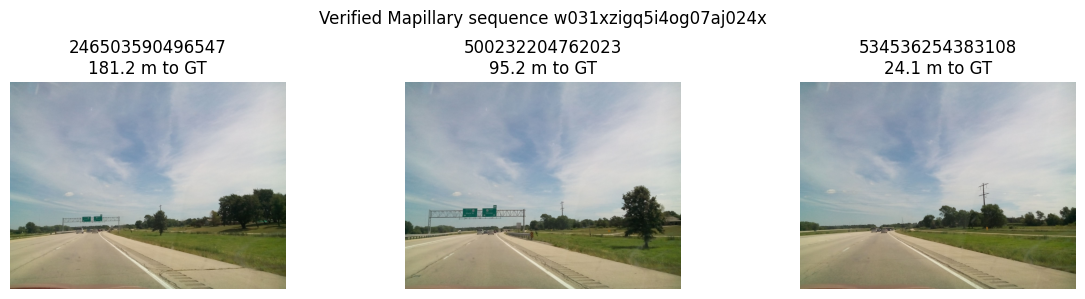

In [4]:
image_paths = []
for i, row in sequence_df.iterrows():
    if not row["download_url"]:
        raise RuntimeError(f"No downloadable image URL for {row['image_id']}.")
    image_path = IMAGE_DIR / f"{i:03d}_{row['image_id']}.jpg"
    if not image_path.exists():
        response = requests.get(row["download_url"], timeout=90)
        response.raise_for_status()
        image_path.write_bytes(response.content)
    image_paths.append(str(image_path))
sequence_df["local_path"] = image_paths
images = [Image.open(path).convert("RGB") for path in image_paths]

fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 3), squeeze=False)
for ax, image, (_, row) in zip(axes[0], images, sequence_df.iterrows()):
    ax.imshow(image)
    ax.set_title(f"{row['image_id']}\n{row['distance_to_gt_m']:.1f} m to GT")
    ax.axis("off")
fig.suptitle(f"Verified Mapillary sequence {sequence_id}")
plt.tight_layout()
montage_path = VIS_DIR / "verified_sequence.png"
fig.savefig(montage_path, dpi=150)
print("Saved:", montage_path)

## 5. SAM3 Automatic Obstruction and Road Segmentation

In [5]:
@dataclass
class MaskDetection:
    frame_idx: int
    prompt: str
    score: float
    box: Tuple[int, int, int, int]
    mask: np.ndarray

def to_numpy(value):
    if hasattr(value, "detach"):
        return value.detach().float().cpu().numpy()
    return np.asarray(value)

def mask_candidate_score(det: MaskDetection, image: Image.Image) -> float:
    x1, y1, x2, y2 = det.box
    area_fraction = float(det.mask.mean())
    centre_y = (y1 + y2) / (2 * image.height)
    overhead_gate = 0.001 <= area_fraction <= 0.25 and centre_y < 0.72
    return det.score + (0.20 if overhead_gate else -1.0)

def run_sam3_on_sequence(images: List[Image.Image]) -> Tuple[Dict[int, List[MaskDetection]], Dict[int, MaskDetection]]:
    if importlib.util.find_spec("sam3") is None:
        raise ImportError("Install the official facebookresearch/sam3 package before running this cell.")
    from sam3.model.sam3_image_processor import Sam3Processor
    from sam3.model_builder import build_sam3_image_model

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if LOCAL_SAM3_CHECKPOINT.exists():
        model = build_sam3_image_model(
            checkpoint_path=str(LOCAL_SAM3_CHECKPOINT), load_from_HF=False
        ).to(device).eval()
    else:
        model = build_sam3_image_model().to(device).eval()
    processor = Sam3Processor(model)
    obstruction_by_frame, road_by_frame = {}, {}
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    for frame_idx, image in enumerate(images):
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=device == "cuda"):
            state = processor.set_image(image)
            obstruction = []
            for prompt in SAM3_PROMPTS:
                result = processor.set_text_prompt(state=state, prompt=prompt)
                for score, box, mask in zip(to_numpy(result["scores"]), to_numpy(result["boxes"]), to_numpy(result["masks"])):
                    if float(score) >= MIN_SAM3_SCORE:
                        obstruction.append(MaskDetection(
                            frame_idx, prompt, float(score), tuple(np.asarray(box, int).tolist()),
                            np.squeeze(mask).astype(bool),
                        ))
            obstruction = sorted(obstruction, key=lambda d: mask_candidate_score(d, image), reverse=True)
            obstruction_by_frame[frame_idx] = [d for d in obstruction if mask_candidate_score(d, image) > 0][:4]

            road_result = processor.set_text_prompt(state=state, prompt=ROAD_PROMPT)
            road_candidates = []
            for score, box, mask in zip(to_numpy(road_result["scores"]), to_numpy(road_result["boxes"]), to_numpy(road_result["masks"])):
                mask = np.squeeze(mask).astype(bool)
                bottom_support = mask[int(mask.shape[0] * 0.72):, :].mean()
                if float(score) >= MIN_SAM3_SCORE and bottom_support > 0.08:
                    road_candidates.append(MaskDetection(
                        frame_idx, ROAD_PROMPT, float(score), tuple(np.asarray(box, int).tolist()), mask
                    ))
        if road_candidates:
            road_by_frame[frame_idx] = max(road_candidates, key=lambda d: d.score + float(d.mask.mean()))
        del state
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return obstruction_by_frame, road_by_frame

sam3_cache = MODEL_DIR / "sam3_masks_v2.npz"
if sam3_cache.exists() and not FORCE_RERUN_MODELS:
    cached = np.load(sam3_cache, allow_pickle=True)
    obstruction_by_frame = cached["obstruction_by_frame"].item()
    road_by_frame = cached["road_by_frame"].item()
    print("Loaded cached SAM3 masks:", sam3_cache)
else:
    obstruction_by_frame, road_by_frame = run_sam3_on_sequence(images)
    np.savez_compressed(
        sam3_cache,
        obstruction_by_frame=np.array(obstruction_by_frame, dtype=object),
        road_by_frame=np.array(road_by_frame, dtype=object),
    )
sam3_summary = pd.DataFrame([
    {
        "frame_idx": i,
        "image_id": sequence_df.iloc[i]["image_id"],
        "obstruction_candidates": len(obstruction_by_frame.get(i, [])),
        "road_mask_found": i in road_by_frame,
    }
    for i in range(len(images))
])
display(sam3_summary)

Loaded cached SAM3 masks: D:\18463\Desktop\capstone\data\depthanything_update_case3\model_outputs\sam3_masks_v2.npz


,frame_idx,image_id,obstruction_candidates,road_mask_found
0,0,246503590496547,0,True
1,1,500232204762023,4,True
2,2,534536254383108,0,True


## 6. Depth Anything V3 Multi-View Metric Inference

In [6]:
def run_da3_sequence(image_paths: List[str]) -> dict:
    if importlib.util.find_spec("depth_anything_3") is None:
        raise ImportError("Install the official ByteDance-Seed/Depth-Anything-3 package first.")
    from depth_anything_3.api import DepthAnything3

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        print("Warning: the nested DA3 multi-view model is large; a CUDA GPU is strongly recommended.")
    model = DepthAnything3.from_pretrained(DA3_MODEL_ID).to(device).eval()
    prediction = model.inference(
        image=image_paths,
        ref_view_strategy="middle",
        export_dir=str(MODEL_DIR / "da3_export"),
        export_format="depth_vis-mini_npz",
    )
    if int(prediction.is_metric) != 1:
        raise RuntimeError(
            f"{DA3_MODEL_ID} returned non-metric output; refusing meter-scale validation."
        )
    result = {
        "depth_m": np.asarray(prediction.depth, dtype=np.float32),
        "is_metric": np.asarray([prediction.is_metric], dtype=np.int8),
    }
    for name in ["intrinsics", "extrinsics", "conf"]:
        value = getattr(prediction, name, None)
        if value is not None:
            result[name] = np.asarray(value, dtype=np.float32)
    del prediction, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

da3_cache = MODEL_DIR / "da3_nested_metric_outputs.npz"
if da3_cache.exists() and not FORCE_RERUN_MODELS:
    cached = np.load(da3_cache)
    da3 = {name: cached[name] for name in cached.files}
    print("Loaded cached DA3 outputs:", da3_cache)
else:
    da3 = run_da3_sequence(image_paths)
    np.savez_compressed(da3_cache, **da3)

print("DA3 model:", DA3_MODEL_ID)
print("Depth shape:", da3["depth_m"].shape)
if int(np.asarray(da3["is_metric"]).ravel()[0]) != 1:
    raise RuntimeError("Cached DA3 result is not flagged as metric; delete it and rerun with the nested metric model.")
print("The nested DA3 model output is treated as meters according to the official model documentation.")

Loaded cached DA3 outputs: D:\18463\Desktop\capstone\data\depthanything_update_case3\model_outputs\da3_nested_metric_outputs.npz
DA3 model: depth-anything/DA3NESTED-GIANT-LARGE-1.1
Depth shape: (3, 378, 504)
The nested DA3 model output is treated as meters according to the official model documentation.


## 7. Automatic Clearance Measurement From Masks and Metric Depth

In [7]:
def resize_depth(depth: np.ndarray, image: Image.Image) -> np.ndarray:
    depth = np.squeeze(np.asarray(depth, dtype=np.float32))
    if depth.shape == (image.height, image.width):
        return depth
    return np.asarray(Image.fromarray(depth, mode="F").resize(image.size, Image.Resampling.BILINEAR))

def default_intrinsics(image: Image.Image, hfov_deg: float = 70.0) -> np.ndarray:
    f = image.width / (2 * math.tan(math.radians(hfov_deg) / 2))
    return np.array([[f, 0, image.width / 2], [0, f, image.height / 2], [0, 0, 1]], dtype=np.float32)

def frame_intrinsics(frame_idx: int, image: Image.Image, depth_shape: Tuple[int, int]) -> np.ndarray:
    if "intrinsics" not in da3:
        return default_intrinsics(image)
    K = np.asarray(da3["intrinsics"][frame_idx], dtype=np.float32).copy()
    src_h, src_w = depth_shape
    K[0] *= image.width / src_w
    K[1] *= image.height / src_h
    return K

def aligned_mask(mask: np.ndarray, image: Image.Image) -> np.ndarray:
    mask = np.squeeze(np.asarray(mask)).astype(bool)
    if mask.shape == (image.height, image.width):
        return mask
    return np.asarray(
        Image.fromarray(mask.astype(np.uint8) * 255).resize(image.size, Image.Resampling.NEAREST)
    ) > 0

def backproject(mask: np.ndarray, depth_m: np.ndarray, K: np.ndarray) -> np.ndarray:
    ys, xs = np.where(mask & np.isfinite(depth_m) & (depth_m > 0))
    z = depth_m[ys, xs]
    x = (xs - K[0, 2]) * z / K[0, 0]
    y = -(ys - K[1, 2]) * z / K[1, 1]
    return np.column_stack([x, y, z]).astype(np.float32)

def fit_ground_plane(points: np.ndarray, iterations: int = 240, tolerance_m: float = 0.16):
    if len(points) < 200:
        return None, 0
    rng = np.random.default_rng(22)
    best, best_count = None, 0
    for _ in range(iterations):
        p0, p1, p2 = points[rng.choice(len(points), 3, replace=False)]
        normal = np.cross(p1 - p0, p2 - p0)
        length = np.linalg.norm(normal)
        if length < 1e-6:
            continue
        normal /= length
        if abs(normal[1]) < 0.55:
            continue
        d = -normal @ p0
        count = int((np.abs(points @ normal + d) < tolerance_m).sum())
        if count > best_count:
            best, best_count = np.r_[normal, d], count
    return best, best_count

def height_above_plane(points: np.ndarray, plane: np.ndarray) -> float:
    a, b, c, d = plane
    lowest = points[points[:, 1] <= np.percentile(points[:, 1], 12)]
    ground_y = -(a * lowest[:, 0] + c * lowest[:, 2] + d) / b
    return float(np.median(lowest[:, 1] - ground_y))

rows = []
for frame_idx, image in enumerate(images):
    if frame_idx not in road_by_frame or not obstruction_by_frame.get(frame_idx):
        continue
    raw_depth = np.squeeze(da3["depth_m"][frame_idx])
    depth_m = resize_depth(raw_depth, image)
    K = frame_intrinsics(frame_idx, image, raw_depth.shape)
    road_mask = aligned_mask(road_by_frame[frame_idx].mask, image)
    road_points = backproject(road_mask, depth_m, K)
    if len(road_points) > 15000:
        road_points = road_points[np.linspace(0, len(road_points) - 1, 15000).astype(int)]
    plane, support = fit_ground_plane(road_points)
    if plane is None:
        continue
    for candidate_idx, det in enumerate(obstruction_by_frame[frame_idx]):
        object_mask = aligned_mask(det.mask, image)
        object_points = backproject(object_mask, depth_m, K)
        if len(object_points) < 50:
            continue
        clearance_m = height_above_plane(object_points, plane)
        rows.append({
            "frame_idx": frame_idx,
            "image_id": sequence_df.iloc[frame_idx]["image_id"],
            "candidate_idx": candidate_idx,
            "prompt": det.prompt,
            "sam3_score": det.score,
            "clearance_m": clearance_m,
            "clearance_ft": clearance_m / 0.3048,
            "ground_plane_support": support,
            "object_pixels": int(object_mask.sum()),
            "object_area_fraction": float(object_mask.mean()),
            "measurement_quality_pass": bool(
                object_mask.mean() >= MIN_MEASURABLE_OBJECT_AREA_FRACTION
                and 0.5 < clearance_m < 12.0
            ),
        })

raw_candidates = pd.DataFrame(rows)
if raw_candidates.empty:
    raise RuntimeError("No fully automatic SAM3 + DA3 clearance candidates were measured.")
raw_candidates.to_csv(OUTPUT_DIR / "raw_clearance_candidates.csv", index=False)
candidates = raw_candidates[raw_candidates["measurement_quality_pass"]].copy()
if candidates.empty:
    raise RuntimeError("SAM3 detected obstructions, but no candidate passed automatic measurable-size and clearance checks.")

# An IDOT vertical-clearance record is the lowest obstruction over the road:
# select the lowest plausible candidate in each frame without looking at its GT value.
frame_results = (
    candidates.sort_values(["frame_idx", "clearance_m", "sam3_score"], ascending=[True, True, False])
    .groupby("frame_idx", as_index=False).first()
)
frame_results["gt_clearance_m"] = float(gt["gt_clearance_m"])
frame_results["gt_clearance_ft"] = float(gt["gt_clearance_ft"])
frame_results["absolute_error_m"] = abs(frame_results["clearance_m"] - frame_results["gt_clearance_m"])
frame_results["absolute_error_ft"] = abs(frame_results["clearance_ft"] - frame_results["gt_clearance_ft"])
frame_results.to_csv(OUTPUT_DIR / "frame_level_validation.csv", index=False)
print(
    f"Automatic measurable-mask threshold: {MIN_MEASURABLE_OBJECT_AREA_FRACTION:.1%}; "
    f"accepted {len(frame_results)} of {raw_candidates['frame_idx'].nunique()} detected frames."
)
display(frame_results)

Automatic measurable-mask threshold: 1.0%; accepted 1 of 1 detected frames.


,frame_idx,image_id,candidate_idx,prompt,sam3_score,clearance_m,clearance_ft,ground_plane_support,object_pixels,object_area_fraction,measurement_quality_pass,gt_clearance_m,gt_clearance_ft,absolute_error_m,absolute_error_ft
0,1,500232204762023,3,sign truss,0.566406,7.803733,25.602798,14982,34446,0.01095,True,5.7404,18.833333,2.063333,6.769465


## 8. Sequence-Level Validation and Automatic QA

In [8]:
estimate_m = float(frame_results["clearance_m"].median())
result = pd.DataFrame([{
    "IDOT_OBJECTID": int(gt["OBJECTID"]),
    "Location": gt["Location"],
    "Description": gt["Description"],
    "verified_sequence_id": sequence_id,
    "anchor_image_id": ANCHOR_MAPILLARY_IMAGE_ID,
    "frames_downloaded": len(sequence_df),
    "frames_measured": len(frame_results),
    "gt_clearance_m": float(gt["gt_clearance_m"]),
    "gt_clearance_ft": float(gt["gt_clearance_ft"]),
    "estimated_clearance_m": estimate_m,
    "estimated_clearance_ft": estimate_m / 0.3048,
    "absolute_error_m": abs(estimate_m - float(gt["gt_clearance_m"])),
    "absolute_error_ft": abs(estimate_m / 0.3048 - float(gt["gt_clearance_ft"])),
    "model": DA3_MODEL_ID,
    "segmentation": "SAM3 text prompts, no manual boxes",
}])
result["measurement_status"] = (
    "multi_frame_target_measurement"
    if len(frame_results) >= 2
    else "single_visible_target_view_with_verified_multiview_depth_context"
)
qa = pd.DataFrame([
    {"check": "sequence_identity_passed", "required": True, "pass": bool(identity_checks["pass"].all())},
    {"check": "multi_view_sequence_used", "required": True, "pass": len(sequence_df) >= MIN_SEQUENCE_FRAMES},
    {"check": "no_manual_regions_used", "required": True, "pass": True},
    {"check": "measurable_mask_area_enforced", "required": True, "pass": bool((frame_results["object_area_fraction"] >= MIN_MEASURABLE_OBJECT_AREA_FRACTION).all())},
    {"check": "at_least_one_automatic_measurement", "required": True, "pass": len(frame_results) >= 1},
    {"check": "finite_sequence_estimate", "required": True, "pass": np.isfinite(estimate_m)},
    {"check": "ransac_ground_support", "required": True, "pass": bool((frame_results["ground_plane_support"] >= 200).all())},
    {
        "check": "multiple_visible_target_views_measured",
        "required": False,
        "pass": len(frame_results) >= 2,
    },
    {
        "check": "ground_truth_agreement_within_1ft",
        "required": False,
        "pass": float(result["absolute_error_ft"].iloc[0]) <= 1.0,
    },
])
result.to_csv(OUTPUT_DIR / "sequence_level_validation.csv", index=False)
qa.to_csv(OUTPUT_DIR / "qa_report.csv", index=False)
display(result)
display(qa)
failed_required = qa[qa["required"] & ~qa["pass"]]
if not failed_required.empty:
    raise RuntimeError("Required automatic QA failed; do not report this estimate as validated.")
if not bool(qa.loc[qa["check"] == "multiple_visible_target_views_measured", "pass"].iloc[0]):
    print("Limitation: only one sequence frame exposes a SAM3-measurable target; DA3 still used the verified multi-view sequence for depth context.")
if not bool(qa.loc[qa["check"] == "ground_truth_agreement_within_1ft", "pass"].iloc[0]):
    print("Validation result: estimate is more than 1 ft from IDOT ground truth; report this case as an accuracy failure, not a successful metric estimate.")

,IDOT_OBJECTID,Location,Description,verified_sequence_id,anchor_image_id,frames_downloaded,frames_measured,gt_clearance_m,gt_clearance_ft,estimated_clearance_m,estimated_clearance_ft,absolute_error_m,absolute_error_ft,model,segmentation,measurement_status
0,5,US20: W OF STATE ST,"US20: W OF STATE ST, SIGN TRUSS, EB: 18-10, EB...",w031xzigq5i4og07aj024x,534536254383108,3,1,5.7404,18.833333,7.803733,25.602798,2.063333,6.769465,depth-anything/DA3NESTED-GIANT-LARGE-1.1,"SAM3 text prompts, no manual boxes",single_visible_target_view_with_verified_multi...


,check,required,pass
0,sequence_identity_passed,True,True
1,multi_view_sequence_used,True,True
2,no_manual_regions_used,True,True
3,measurable_mask_area_enforced,True,True
4,at_least_one_automatic_measurement,True,True
5,finite_sequence_estimate,True,True
6,ransac_ground_support,True,True
7,multiple_visible_target_views_measured,False,False
8,ground_truth_agreement_within_1ft,False,False


Limitation: only one sequence frame exposes a SAM3-measurable target; DA3 still used the verified multi-view sequence for depth context.
Validation result: estimate is more than 1 ft from IDOT ground truth; report this case as an accuracy failure, not a successful metric estimate.


## 9. Automatic Visualization Export

Saved: D:\18463\Desktop\capstone\data\depthanything_update_case3\visualizations\sam3_da3_sequence_validation.png
Final outputs: D:\18463\Desktop\capstone\data\depthanything_update_case3


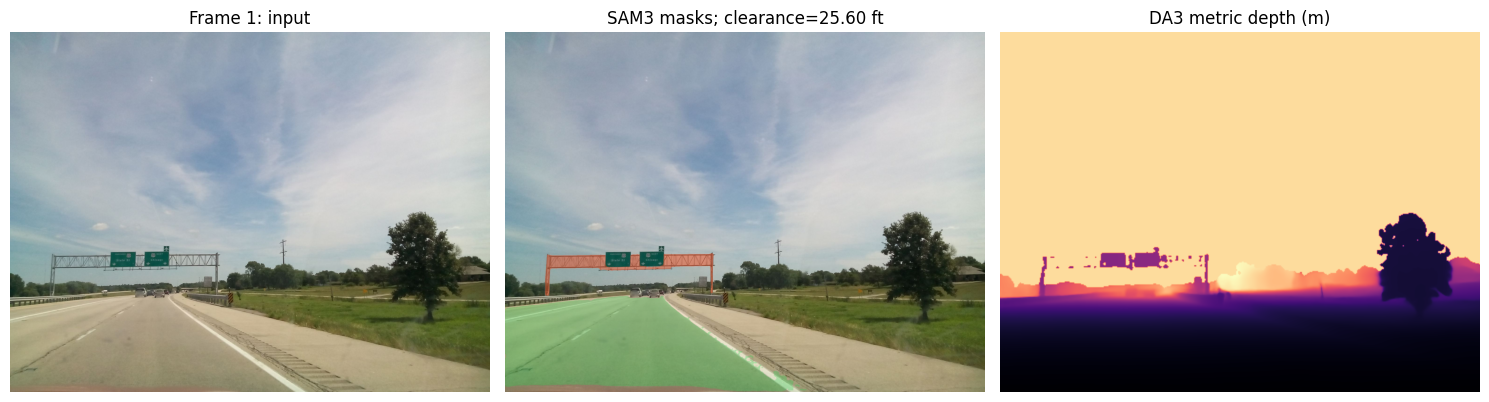

In [9]:
measured_frames = set(frame_results["frame_idx"].astype(int))
fig, axes = plt.subplots(len(measured_frames), 3, figsize=(15, 4 * len(measured_frames)), squeeze=False)
for row_idx, frame_idx in enumerate(sorted(measured_frames)):
    image = images[frame_idx].copy().convert("RGBA")
    winning = frame_results.loc[frame_results["frame_idx"] == frame_idx].iloc[0]
    obstruction = obstruction_by_frame[frame_idx][int(winning["candidate_idx"])]
    object_mask = aligned_mask(obstruction.mask, images[frame_idx])
    road_mask = aligned_mask(road_by_frame[frame_idx].mask, images[frame_idx])
    overlay = Image.new("RGBA", image.size, (0, 0, 0, 0))
    overlay.paste(Image.new("RGBA", image.size, (255, 70, 20, 110)), mask=Image.fromarray(object_mask.astype(np.uint8) * 255))
    overlay.paste(Image.new("RGBA", image.size, (40, 210, 80, 75)), mask=Image.fromarray(road_mask.astype(np.uint8) * 255))
    shown = Image.alpha_composite(image, overlay)
    axes[row_idx, 0].imshow(images[frame_idx])
    axes[row_idx, 0].set_title(f"Frame {frame_idx}: input")
    axes[row_idx, 1].imshow(shown)
    axes[row_idx, 1].set_title(f"SAM3 masks; clearance={winning['clearance_ft']:.2f} ft")
    depth = resize_depth(da3["depth_m"][frame_idx], images[frame_idx])
    axes[row_idx, 2].imshow(depth, cmap="magma")
    axes[row_idx, 2].set_title("DA3 metric depth (m)")
    for ax in axes[row_idx]:
        ax.axis("off")
plt.tight_layout()
visual_path = VIS_DIR / "sam3_da3_sequence_validation.png"
fig.savefig(visual_path, dpi=150)
print("Saved:", visual_path)
print("Final outputs:", OUTPUT_DIR)